<a href="https://colab.research.google.com/github/MBR4V0/Iniciacao-Cientifica/blob/main/Analise_MONGO1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pymongo dnspython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pymongo]


In [ ]:
!pip install -q pymongo dnspython pandas odfpy openpyxl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import userdata
from pymongo import MongoClient

# Recupera a URL protegida
MONGO_URI = userdata.get('MONGO_URI')

# Cria a conexão
client = MongoClient(
    MONGO_URI,
    serverSelectionTimeoutMS=10000
)

# Testa a conexão
try:
    client.admin.command('ping')
    print(" CONECTADO AO MONGODB COM SUCESSO!")
except Exception as e:
    print(" ERRO NA CONEXÃO:", e)

 CONECTADO AO MONGODB COM SUCESSO!


In [ ]:

import pandas as pd
from pymongo import MongoClient
from google.colab import files, userdata
import io
import os

# ====================================
# 1. CONECTAR AO MONGODB
# ====================================

MONGO_URI = userdata.get("MONGO_URI")

client = MongoClient(
    MONGO_URI,
    serverSelectionTimeoutMS=15000
)

client.admin.command("ping")

print("✅ MongoDB conectado!")

# ====================================
# 2. DEFINIR BANCO E COLEÇÃO
# ====================================

db = client["alunos"]
collection = db["importacao_csv"]

# ====================================
# 3. SELECIONAR ARQUIVO
# ====================================

print("Selecione sua planilha:")
uploaded = files.upload()

nome_arquivo = list(uploaded.keys())[0]

extensao = os.path.splitext(nome_arquivo)[1].lower()

# ====================================
# 4. LER AUTOMATICAMENTE
# ====================================

arquivo = io.BytesIO(uploaded[nome_arquivo])

if extensao == ".ods":
    df = pd.read_excel(arquivo, engine="odf")

elif extensao in [".xlsx", ".xls"]:
    df = pd.read_excel(arquivo)

elif extensao == ".csv":
    try:
        df = pd.read_csv(
            arquivo,
            sep=None,
            engine="python",
            encoding="utf-8"
        )
    except UnicodeDecodeError:
        arquivo.seek(0)
        df = pd.read_csv(
            arquivo,
            sep=None,
            engine="python",
            encoding="latin1"
        )

else:
    raise ValueError("Formato não suportado: " + extensao)

print("\n✅ Planilha carregada!")
print("Arquivo:", nome_arquivo)
print("Registros:", len(df))
print("Colunas:", list(df.columns))

display(df.head())

# ====================================
# 5. IMPORTAR PARA O MONGODB
# ====================================

dados = df.astype(object).where(
    pd.notna(df), None
).to_dict(orient="records")

if dados:
    resultado = collection.insert_many(dados)

    print("\n🎉 IMPORTAÇÃO REALIZADA!")
    print("Registros enviados:", len(resultado.inserted_ids))
    print("Banco:", db.name)
    print("Coleção:", collection.name)

else:
    print("A planilha está vazia.")

# ====================================
# 6. CONFERIR IMPORTAÇÃO
# ====================================

print(
    "\nTotal de documentos na coleção:",
    collection.count_documents({})
)

client.close()

✅ MongoDB conectado!
Selecione sua planilha:


Saving BRCA.datafreeze.20120227.xlsx to BRCA.datafreeze.20120227.xlsx

✅ Planilha carregada!
Arquivo: BRCA.datafreeze.20120227.xlsx
Registros: 466
Colunas: ['Sample', 'bcr_patient_barcode', 'Tissue', 'PAM50', 'Triple Negative', 'Batch', 'Histology', 'UNC.microarray', 'BCGSC.miRNAseqs', 'Broad.CN', 'Methylation', 'WU.seq.20111103', 'RPPA', 'Integration.Freeze', 'Integration.RPPA.Freeze.batch1']


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,Sample,bcr_patient_barcode,Tissue,PAM50,Triple Negative,Batch,Histology,UNC.microarray,BCGSC.miRNAseqs,Broad.CN,Methylation,WU.seq.20111103,RPPA,Integration.Freeze,Integration.RPPA.Freeze.batch1
0,TCGA-A1-A0SK-01A,TCGA-A1-A0SK,Tumor,Basal,TN,72,Breast - Other,1,1,1,1,1,1,Freeze.466,Freeze.348
1,TCGA-A2-A0ST-01A,TCGA-A2-A0ST,Tumor,Basal,TN,72,Infiltrating Ductal Carcinoma,1,1,1,1,1,1,Freeze.466,Freeze.348
2,TCGA-A2-A0SX-01A,TCGA-A2-A0SX,Tumor,Basal,TN,72,Infiltrating Ductal Carcinoma,1,1,1,1,1,1,Freeze.466,Freeze.348
3,TCGA-A2-A0T2-01A,TCGA-A2-A0T2,Tumor,Basal,TN,72,Infiltrating Ductal Carcinoma,1,1,1,1,1,1,Freeze.466,Freeze.348
4,TCGA-BH-A0E6-01A,TCGA-BH-A0E6,Tumor,Basal,TN,56,Infiltrating Ductal Carcinoma,1,1,1,1,1,1,Freeze.466,Freeze.348



🎉 IMPORTAÇÃO REALIZADA!
Registros enviados: 466
Banco: alunos
Coleção: importacao_csv

Total de documentos na coleção: 466


In [ ]:
!pip install -q pymongo dnspython pandas seaborn matplotlib

MONGODB CONECTADO COM SUCESSO!

BASE CARREGADA COM SUCESSO!
Total de registros: 466
Total de variáveis: 15

1. DIAGNOSTICO GERAL
Quantidade de registros: 466
Quantidade de colunas: 15
Total de células: 6990
Registros duplicados: 0


,Tipo de dado,Valores preenchidos,Valores ausentes,% Ausentes,Valores únicos
Sample,object,466,0,0.00,466
bcr_patient_barcode,object,466,0,0.00,463
Tissue,object,466,0,0.00,2
PAM50,object,466,0,0.00,5
Triple Negative,object,77,389,83.48,1
Batch,int64,466,0,0.00,10
Histology,object,466,0,0.00,9
UNC.microarray,int64,466,0,0.00,1
BCGSC.miRNAseqs,int64,466,0,0.00,1
Broad.CN,int64,466,0,0.00,1



2. ESTATISTICA DESCRITIVA


,count,mean,std,min,25%,50%,75%,max
Batch,466.0,71.742489,17.547300,47.0,56.0,72.0,85.0,103.0
UNC.microarray,466.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
BCGSC.miRNAseqs,466.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
Broad.CN,466.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
Methylation,466.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
WU.seq.20111103,466.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
RPPA,466.0,0.776824,0.416823,0.0,1.0,1.0,1.0,1.0


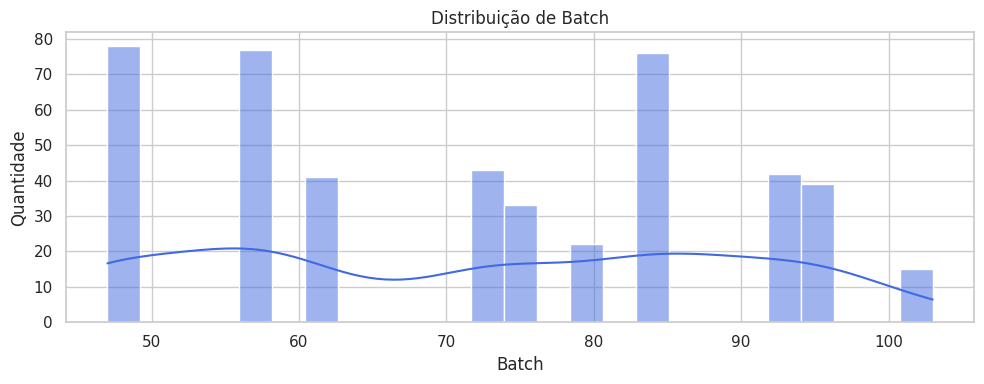

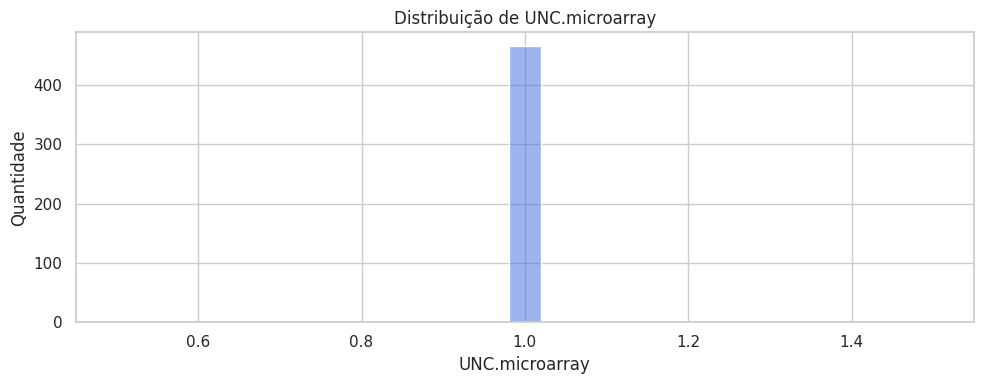

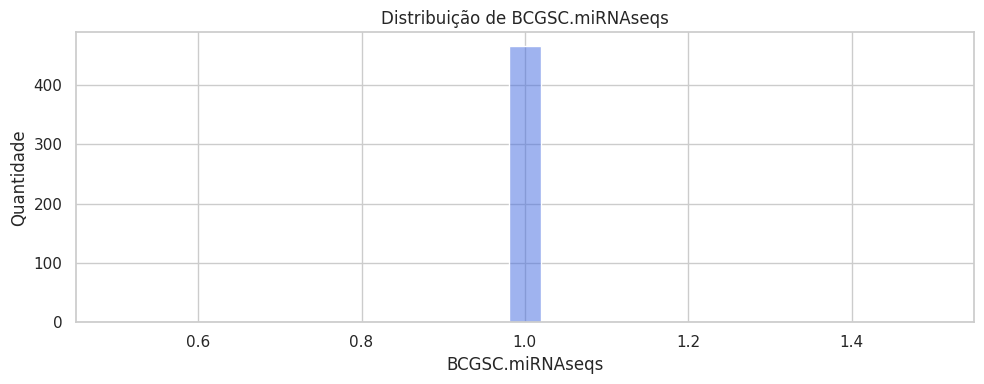

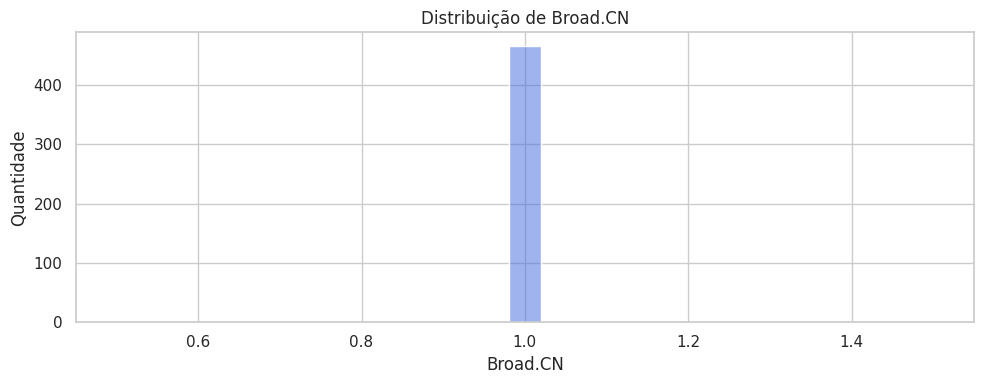

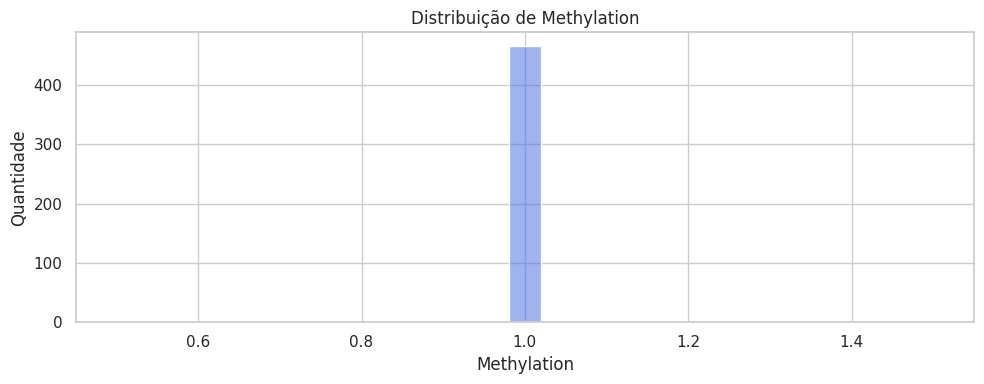

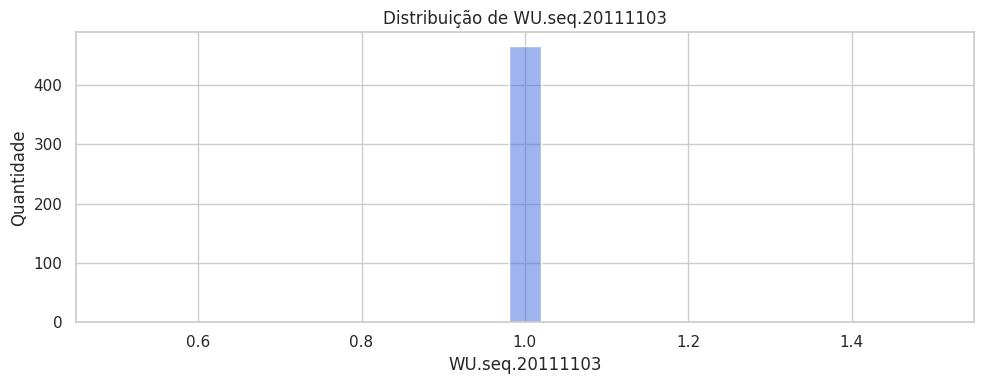

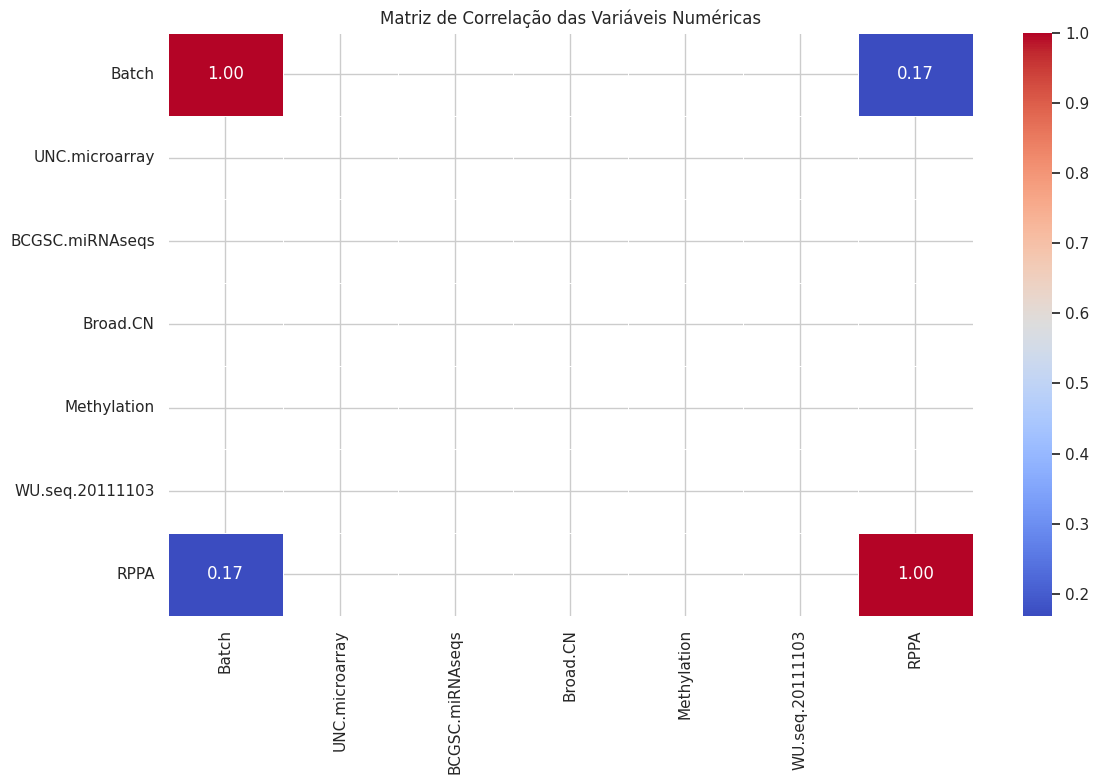


3. ANALISE DAS VARIAVEIS CATEGORICAS

FREQUÊNCIA: Sample


,Quantidade
Sample,
TCGA-A1-A0SK-01A,1
TCGA-A2-A0ST-01A,1
TCGA-A2-A0SX-01A,1
TCGA-A2-A0T2-01A,1
TCGA-BH-A0E6-01A,1
TCGA-A1-A0SO-01A,1
TCGA-A2-A0T0-01A,1
TCGA-A2-A0YM-01A,1
TCGA-AO-A0JL-01A,1


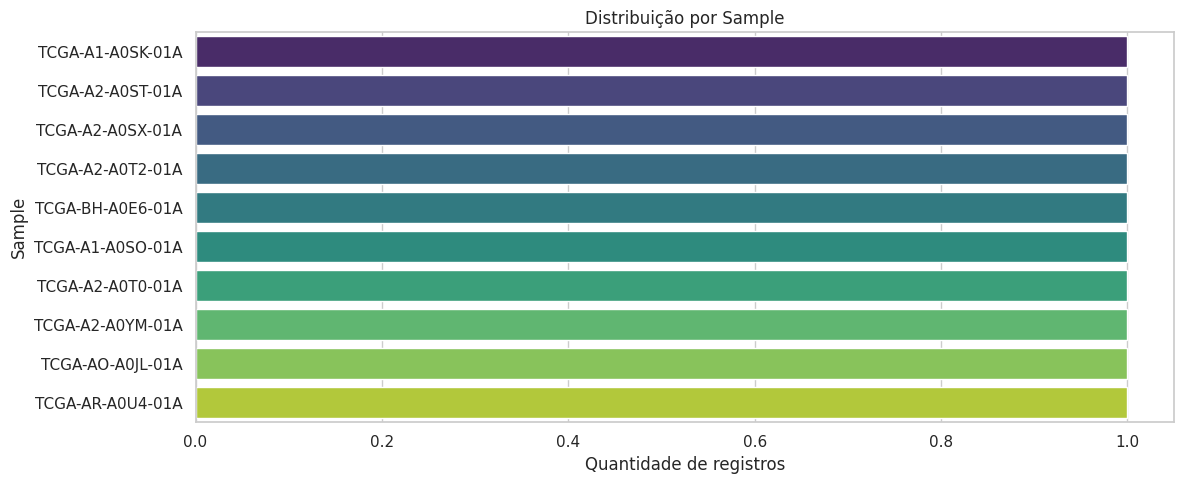


FREQUÊNCIA: bcr_patient_barcode


,Quantidade
bcr_patient_barcode,
TCGA-E2-A15E,2
TCGA-E2-A15K,2
TCGA-E2-A15A,2
TCGA-AR-A1AV,1
TCGA-AR-A0U3,1
TCGA-AR-A0TZ,1
TCGA-AR-A0TQ,1
TCGA-AO-A0JD,1
TCGA-AO-A0JC,1


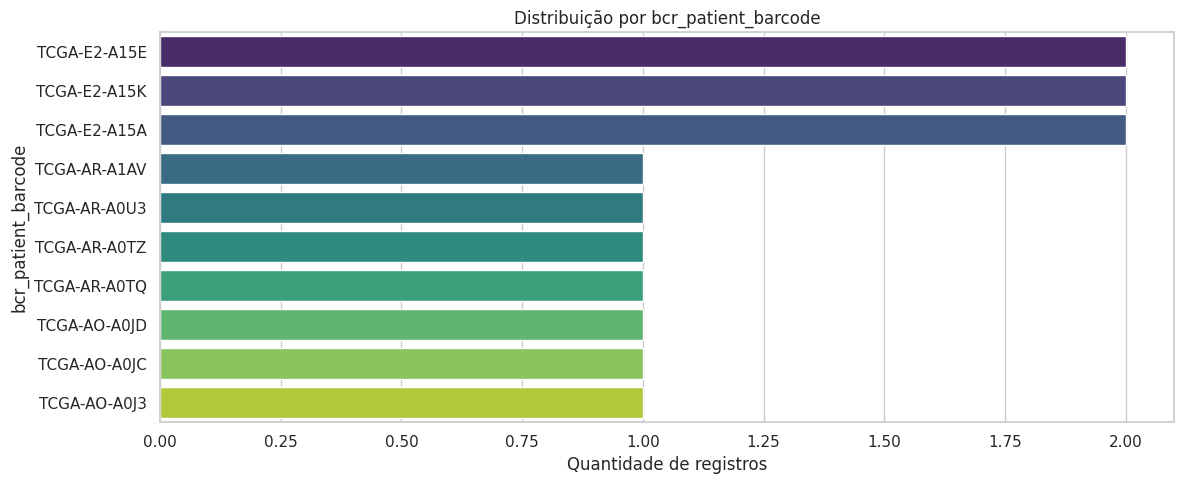


FREQUÊNCIA: Tissue


,Quantidade
Tissue,
Tumor,463
Metastatic,3


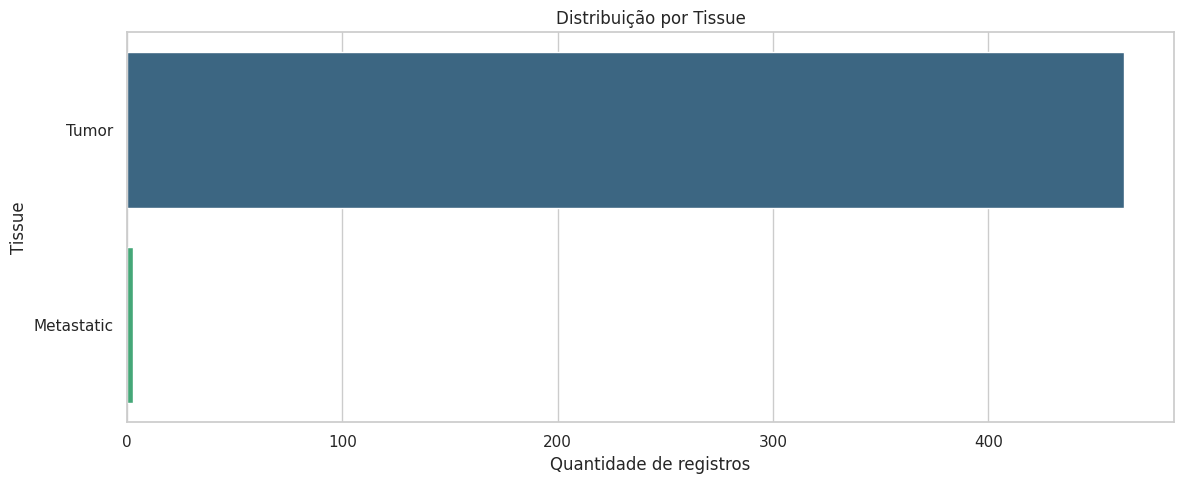


FREQUÊNCIA: PAM50


,Quantidade
PAM50,
LumA,210
LumB,114
Basal,81
Her2,53
Normal,8


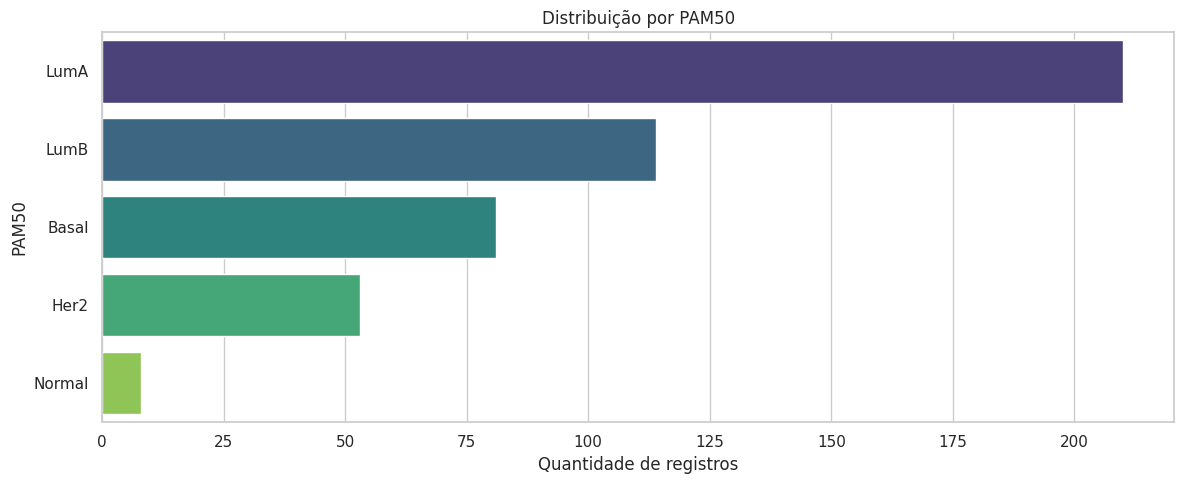


FREQUÊNCIA: Triple Negative


,Quantidade
Triple Negative,
Não informado,389
TN,77


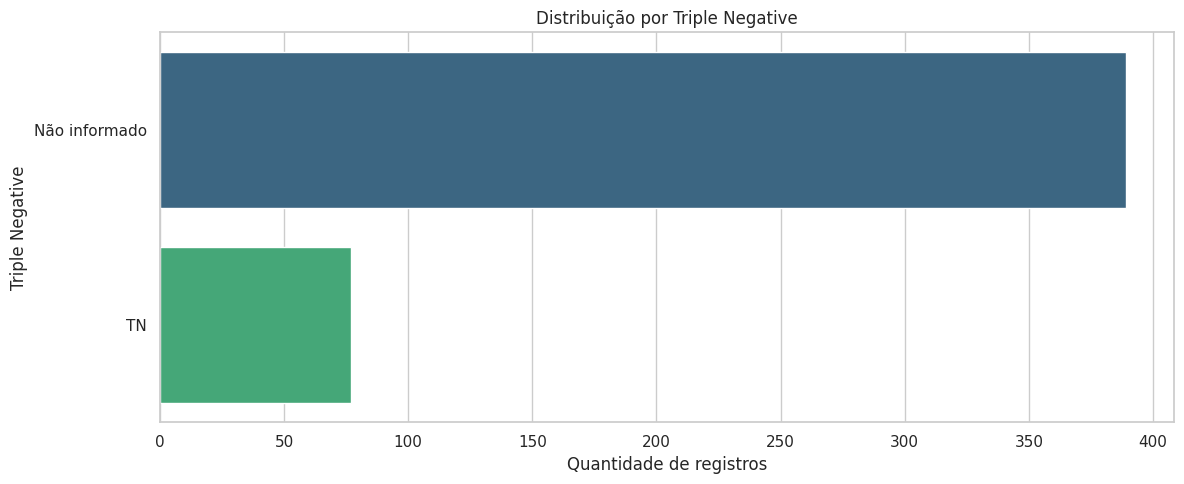


FREQUÊNCIA: Histology


,Quantidade
Histology,
Infiltrating Ductal Carcinoma,341
Breast Ductal adenocarcinoma,58
Infiltrating Lobular Carcinoma,31
Mixed Histology,18
Breast Lobular adenocarcinoma,8
Breast - Other,7
Medullary Carcinoma,1
Mucinous Carcinoma,1
Breast Ductal Adenocarcinoma,1


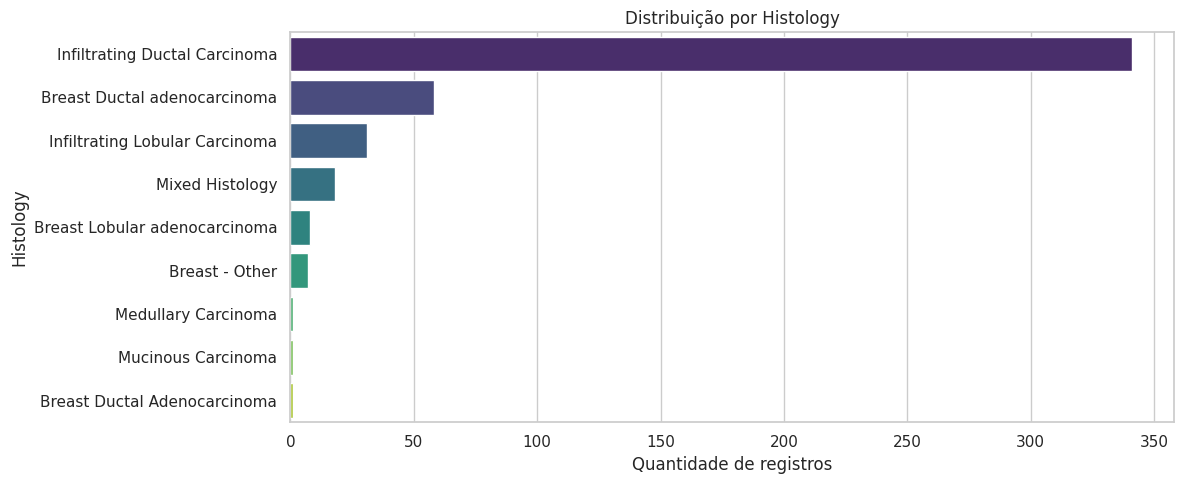


RELATORIO FINAL
Total de registros: 466
Total de variáveis: 15
Variáveis numéricas: 7
Variáveis categóricas: 8
Total de dados ausentes: 507
Registros duplicados: 0

ANÁLISE CONCLUÍDA!


In [ ]:

# ==========================================================
# ANALISE QUANTITATIVA - MONGODB + PANDAS + SEABORN
# ==========================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from pymongo import MongoClient
from google.colab import userdata
from IPython.display import display

# ==========================================================
# 1. CONEXAO COM MONGODB
# ==========================================================

MONGO_URI = userdata.get("MONGO_URI")

client = MongoClient(MONGO_URI)

db = client["alunos"]
collection = db["importacao_csv"]

client.admin.command("ping")

print("MONGODB CONECTADO COM SUCESSO!")

# ==========================================================
# 2. BUSCAR A BASE DIRETAMENTE NO MONGODB
# ==========================================================

documentos = list(collection.find({}, {"_id": 0}))

df = pd.DataFrame(documentos)

if df.empty:
    raise ValueError("A coleção não possui documentos.")

print("\nBASE CARREGADA COM SUCESSO!")
print("Total de registros:", len(df))
print("Total de variáveis:", len(df.columns))

# ==========================================================
# 3. CONFIGURACAO VISUAL
# ==========================================================

sns.set_theme(
    style="whitegrid",
    palette="viridis",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (12, 6)

# ==========================================================
# 4. DIAGNOSTICO GERAL DA BASE
# ==========================================================

print("\n" + "="*60)
print("1. DIAGNOSTICO GERAL")
print("="*60)

print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])
print("Total de células:", df.size)
print("Registros duplicados:", df.duplicated().sum())

diagnostico = pd.DataFrame({
    "Tipo de dado": df.dtypes.astype(str),
    "Valores preenchidos": df.notna().sum(),
    "Valores ausentes": df.isna().sum(),
    "% Ausentes": (df.isna().mean() * 100).round(2),
    "Valores únicos": df.nunique()
})

display(diagnostico)

# ==========================================================
# 5. ESTATISTICA DESCRITIVA
# ==========================================================

print("\n" + "="*60)
print("2. ESTATISTICA DESCRITIVA")
print("="*60)

# Identificar variáveis numéricas
df_numerico = df.select_dtypes(include=np.number)

if not df_numerico.empty:

    estatisticas = df_numerico.describe().T

    display(estatisticas)

else:
    print("Não foram identificadas colunas numéricas.")

# ==========================================================
# 6. DISTRIBUICAO DAS VARIAVEIS NUMERICAS
# ==========================================================

if not df_numerico.empty:

    colunas_numericas = df_numerico.columns[:6]

    for coluna in colunas_numericas:

        plt.figure(figsize=(10, 4))

        sns.histplot(
            data=df,
            x=coluna,
            kde=True,
            bins=25,
            color="royalblue"
        )

        plt.title(f"Distribuição de {coluna}")
        plt.xlabel(coluna)
        plt.ylabel("Quantidade")
        plt.tight_layout()
        plt.show()

# ==========================================================
# 7. ANALISE DE CORRELACAO
# ==========================================================

if len(df_numerico.columns) >= 2:

    plt.figure(figsize=(12, 8))

    correlacao = df_numerico.corr()

    sns.heatmap(
        correlacao,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=.5
    )

    plt.title("Matriz de Correlação das Variáveis Numéricas")
    plt.tight_layout()
    plt.show()

# ==========================================================
# 8. ANALISE DAS VARIAVEIS CATEGORICAS
# ==========================================================

df_categorico = df.select_dtypes(
    include=["object", "category", "string"]
)

print("\n" + "="*60)
print("3. ANALISE DAS VARIAVEIS CATEGORICAS")
print("="*60)

for coluna in df_categorico.columns[:6]:

    frequencia = (
        df[coluna]
        .fillna("Não informado")
        .astype(str)
        .value_counts()
        .head(10)
    )

    print(f"\nFREQUÊNCIA: {coluna}")

    display(frequencia.to_frame("Quantidade"))

    plt.figure(figsize=(12, 5))

    sns.barplot(
        x=frequencia.values,
        y=frequencia.index,
        hue=frequencia.index,
        palette="viridis",
        legend=False
    )

    plt.title(f"Distribuição por {coluna}")
    plt.xlabel("Quantidade de registros")
    plt.ylabel(coluna)
    plt.tight_layout()
    plt.show()

# ==========================================================
# 9. RESUMO FINAL
# ==========================================================

print("\n" + "="*60)
print("RELATORIO FINAL")
print("="*60)

print(f"Total de registros: {len(df):,}")
print(f"Total de variáveis: {len(df.columns)}")
print(f"Variáveis numéricas: {len(df_numerico.columns)}")
print(f"Variáveis categóricas: {len(df_categorico.columns)}")
print(f"Total de dados ausentes: {df.isna().sum().sum():,}")
print(f"Registros duplicados: {df.duplicated().sum():,}")

print("\nANÁLISE CONCLUÍDA!")

client.close()